To be able to predict the output tokens, we first have to do the tokenization ourselves. I will use the Vicuna tokenizer specific to the Vicuna-13b model.

In [1]:
import pandas as pd

df = pd.read_parquet("../data/processed/combined_filtered_english_only.parquet")

In [2]:
df.iloc[0]["conversation"]

array([{'content': "Beside OFAC's selective sanction that target the listed individiuals and entities, please elaborate on the other types of US's sanctions, for example, comprehensive and sectoral sanctions. Please be detailed as much as possible", 'role': 'user'},
       {'content': "The United States has a number of different types of sanctions that it can use to achieve its foreign policy goals, including both selective and comprehensive sanctions.\n\nSelective sanctions are targeted at specific individuals or entities that are believed to be engaged in activities that are contrary to US interests. These sanctions can take a variety of forms, including asset freezes, travel bans, and restrictions on financial transactions. The Office of Foreign Assets Control (OFAC) is the US government agency responsible for implementing and enforcing these types of sanctions.\n\nComprehensive sanctions, on the other hand, are more broadly based and aim to restrict entire sectors of a country's ec

The conversation information is stored in a very specific way. The entire conversation is stored together, with content dictionaries and flags for the role (user or assistant). There are two options here:

1. Only analyze the first turn
2. Analyze all turns

The second option leads to a more rich analysis, but it requires more data processing. We will have to re-structure the dataset. Each conversation_id will now need to have a row for each individual turn of the conversation. So the new data structure will have conversation_id, turn, user prompt, assistant response, openai_moderation flag, redacted as its columns. We do not need to store language or model, as it is the same for every remaining row.

In [3]:
rows = []
for index, row in df.iterrows():
    if index % 10000 == 0:
        print(f"Index {index}")

    conversation = row["conversation"]
    moderation = row["openai_moderation"]

    turn_number = 0

    for i in range(len(conversation) - 1):
        current_message = conversation[i]
        next_message = conversation[i + 1]

        if current_message["role"] == "user" and next_message["role"] == "assistant":
            turn_number += 1

            user_prompt = current_message["content"]
            assistant_response = next_message["content"]

            rows.append({
                "conversation_id": row["conversation_id"],
                "turn": turn_number,
                "user_prompt": user_prompt,
                "assistant_response": assistant_response,
                "user_moderation_flag": moderation[i]["flagged"],
                "assistant_moderation_flag": moderation[i + 1]["flagged"],
                "redacted": row["redacted"]
            })

new_df = pd.DataFrame(rows)

Index 0
Index 10000
Index 20000
Index 30000
Index 40000
Index 50000
Index 60000
Index 70000
Index 80000
Index 90000
Index 100000
Index 110000
Index 120000
Index 130000
Index 140000
Index 150000
Index 160000
Index 170000
Index 180000
Index 190000
Index 200000
Index 210000
Index 220000
Index 230000
Index 240000
Index 250000
Index 260000
Index 270000
Index 280000
Index 290000
Index 300000
Index 310000
Index 320000
Index 330000
Index 340000
Index 350000
Index 360000
Index 370000


# Verifying new data

We can verify the data in a few ways: 

1. The sum of turn from the original dataset should equal the number of rows in the new dataset.
2. The number of unique conversation ids should be the same
3. The total number of flagged messages should be the same

In [4]:
import numpy as np

total_turns = np.sum(df["turn"])
number_unique_turns = len(new_df)

print(f"Total turns from original dataset: {total_turns}\nNumber of instances in new dataset: {number_unique_turns}")

Total turns from original dataset: 791076
Number of instances in new dataset: 791076


In [5]:
unique_ids_og = df["conversation_id"].nunique()
unique_ids_new = new_df["conversation_id"].nunique()

print(f"Number of unique OG: {unique_ids_og}\nNumber of unique new: {unique_ids_new}")

Number of unique OG: 374394
Number of unique new: 374394


In [6]:
flagged_count_og = 0

for index, row in df.iterrows():
    for cat_dict in row["openai_moderation"]:
        if cat_dict["flagged"] == True:
            flagged_count_og += 1

flagged_count_new = (
    new_df["user_moderation_flag"].sum()
    + new_df["assistant_moderation_flag"].sum()
)

print(f"Old flag count: {flagged_count_og}\nNew flag count: {flagged_count_new}")

Old flag count: 48940
New flag count: 48940


Through these checks it appears we transformed the data correctly

# Cleaning

In the earlier conversation example, we saw content that was blank. Those need to be removed.

In [7]:
new_df["user_prompt"].value_counts().to_dict()

{"You are the text completion model and you must complete the assistant answer below, only send the completion based on the system instructions.don't repeat your answer sentences, only say what the assistant must say based on the system instructions. repeating same thing in same answer not allowed.\nuser: Who are you?\nassistant: ": 8923,
 'hello': 5349,
 'continue': 3364,
 'Hello': 3135,
 'Continue': 679,
 'hey': 598,
 'Who are you?': 575,
 'NAME_1': 524,
 'who are you': 480,
 'test': 463,
 'no': 462,
 'who are you?': 450,
 'Hello!': 414,
 'Who is NAME_1?': 382,
 'Continue ': 368,
 'Hey': 335,
 'yes': 309,
 'YOUR INPUT VIOLATES OUR CONTENT MODERATION GUIDELINES. PLEASE TRY AGAIN.': 297,
 'No': 283,
 'What is your name?': 243,
 'go on': 234,
 'more': 234,
 'who is NAME_1': 208,
 'How are you?': 196,
 'Yes': 194,
 'hi': 188,
 'NAME_1 NAME_2': 187,
 'tell me a joke': 182,
 'hi there': 178,
 'i have a question': 178,
 'What can you do?': 164,
 '1': 162,
 'Please explain in 40 words, which

In [8]:
filtered_df = new_df[(new_df["user_prompt"].str.strip() != "") & (new_df["assistant_response"].str.strip() != "")]

print(f"Original length {len(new_df)}\nFiltered length: {len(filtered_df)}")

Original length 791076
Filtered length: 780609


In [9]:
filtered_df.isna().sum()

conversation_id              0
turn                         0
user_prompt                  0
assistant_response           0
user_moderation_flag         0
assistant_moderation_flag    0
redacted                     0
dtype: int64

# Tokenization

Now we will tokenize the user prompt and assistant response, and keep track of historial token usage for same conversations.

This tokenizer is for the specific model in this analysis

In [10]:
import transformers
import sentencepiece
from transformers import LlamaTokenizer

tokenizer = LlamaTokenizer.from_pretrained(
    "lmsys/vicuna-13b-v1.3"
)

def count_tokens(text):
    return len(tokenizer.encode(text, add_special_tokens=False, truncation=False))

print(count_tokens("Hello, how are you?"))

c:\Users\tyler\anaconda3\envs\terminal\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
You are using the default legacy behaviour of the <class 'transformers.models.llama.tokenization_llama.LlamaTokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565 - if you loaded a llama tokenizer from a GGUF file you can ignore this message


6


Apply function to prompt and response

In [11]:
filtered_df["prompt_tokens"] = filtered_df["user_prompt"].apply(count_tokens)
filtered_df["response_tokens"] = filtered_df["assistant_response"].apply(count_tokens)

Token indices sequence length is longer than the specified maximum sequence length for this model (2547 > 2048). Running this sequence through the model will result in indexing errors
C:\Users\tyler\AppData\Local\Temp\ipykernel_16892\1173364157.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df["prompt_tokens"] = filtered_df["user_prompt"].apply(count_tokens)
C:\Users\tyler\AppData\Local\Temp\ipykernel_16892\1173364157.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df["response_to

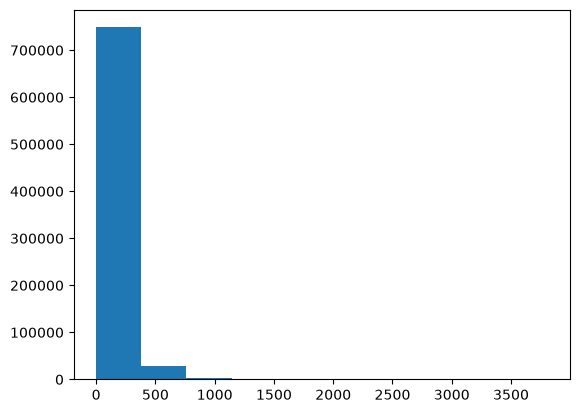

In [13]:
import matplotlib.pyplot as plt

plt.hist(filtered_df["prompt_tokens"])
plt.show()

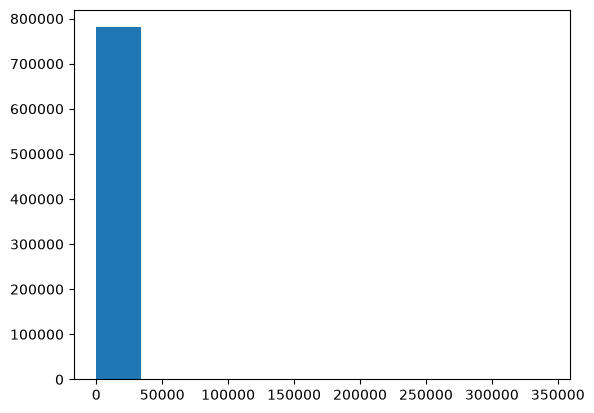

In [15]:
import matplotlib.pyplot as plt

plt.hist(filtered_df["response_tokens"])
plt.show()

In [ ]:
filtered_df.to_parquet("../data/processed/combined_english_with_tokens", index=False)